In [49]:
%pip install ucimlrepo
%pip install pandas
%pip install datetime

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [50]:
from ucimlrepo import fetch_ucirepo 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime

In [51]:
mushroom = fetch_ucirepo(id=73) 
  
X = mushroom.data.features 
y = mushroom.data.targets 
  
# print(X.head())
# print(X.shape)
# print(y.head())
# print(y.shape)


X = pd.get_dummies(X)

# print(X.head())
# print(X.shape)

y = y.iloc[:, 0].map({'e': 0, 'p': 1}).values
# one-hot encoding

# print(y[:20])
# print(y.shape)
# print(np.unique(y))

In [52]:
indices = np.arange(len(X))

# seed = int(datetime.now().timestamp())
seed = 34
np.random.seed(seed)
print("Использованный seed:", seed)

np.random.shuffle(indices)



TRAIN_DATA_PERCENT = 80
split_index = int(len(X) * TRAIN_DATA_PERCENT / 100)

train_indices = indices[:split_index]
test_indices = indices[split_index:]

X_train = X.values[train_indices]
y_train = y[train_indices]
X_test = X.values[test_indices]
y_test = y[test_indices]


Y_train = np.zeros((len(y_train), 2))
Y_train[np.arange(len(y_train)), y_train] = 1
Y_test = np.zeros((len(y_test), 2))
Y_test[np.arange(len(y_test)), y_test] = 1

# print("X_train:", X_train.shape)
# print("X_test:", X_test.shape)
# print("y_train:", y_train.shape)
# print("y_test:", y_test.shape)
print(y_train[:5])
print(Y_train[:5])

Использованный seed: 34
[0 1 1 0 0]
[[1. 0.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]]


In [53]:
class MLP:
    def __init__(self, learning_rate=0.01, n_iterations=10):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

        self.W1 = np.random.randn(116, 32) * np.sqrt(1 / 116)
        self.b1 = np.zeros(32)
        self.W2 = np.random.randn(32, 16) * np.sqrt(1 / 32)
        self.b2 = np.zeros(16)
        self.W3 = np.random.randn(16, 2) * np.sqrt(1 / 16)
        self.b3 = np.zeros(2)

        self.errors_history = []

    def _sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def _forward(self, X):
        # W1
        Z1 = X @ self.W1 + self.b1
        A1 = self._sigmoid(Z1)
        # W2
        Z2 = A1 @ self.W2 + self.b2
        A2 = self._sigmoid(Z2)
        # W3
        Z3 = A2 @ self.W3 + self.b3
        A3 = self._sigmoid(Z3)

        return A1, A2, A3

    def _loss(self, A3, Y):
        loss = np.mean(np.sum((A3 - Y) ** 2, axis=1)) / 2
        return loss

    def _sigmoid_derivative(self, x):
        return x * (1 - x)

    def _backward(self, X, Y, A1, A2, A3):

        n = X.shape[0]

        dA3 = A3 - Y
        dZ3 = dA3 * self._sigmoid_derivative(A3)
        dW3 = A2.T @ dZ3 / n
        db3 = np.mean(dZ3, axis=0)

        dA2 = dZ3 @ self.W3.T
        dZ2 = dA2 * self._sigmoid_derivative(A2)
        dW2 = A1.T @ dZ2 / n
        db2 = np.mean(dZ2, axis=0)

        dA1 = dZ2 @ self.W2.T
        dZ1 = dA1 * self._sigmoid_derivative(A1)
        dW1 = X.T @ dZ1 / n
        db1 = np.mean(dZ1, axis=0)


        self.W3 -= self.learning_rate * dW3
        self.b3 -= self.learning_rate * db3
        self.W2 -= self.learning_rate * dW2
        self.b2 -= self.learning_rate * db2
        self.W1 -= self.learning_rate * dW1
        self.b1 -= self.learning_rate * db1

        # print(
        #     "dW1:", np.mean(np.abs(dW1)),
        #     "dW2:", np.mean(np.abs(dW2)),
        #     "dW3:", np.mean(np.abs(dW3))
        # )

    def fit(self, X, Y):
        self.errors_history = []

        for iteration in range(self.n_iterations):
            A1, A2, A3 = self._forward(X)

            loss = self._loss(A3, Y)

            self.errors_history.append(loss)

            self._backward(X, Y, A1, A2, A3)

        return self

    def predict(self, X):
        _, _, A3 = self._forward(X)

        predictions = np.argmax(A3, axis=1)

        return predictions

    def predict_proba(self, X):
        _, _, A3 = self._forward(X)

        return A3

learning rate = 0.1, accuracy = 0.979, loss = 0.03031


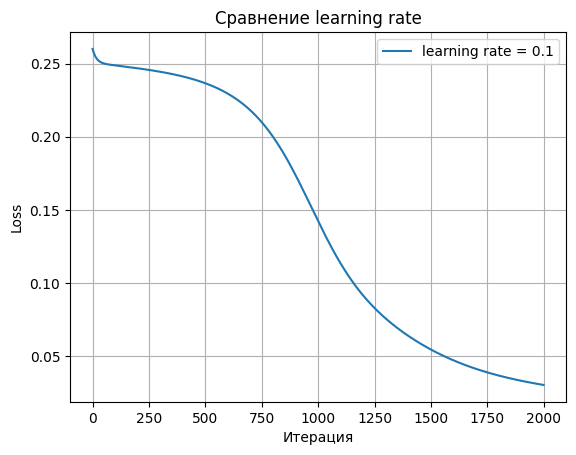

In [54]:
learning_rates = [0.1]

for learning_rate in learning_rates:
    np.random.seed(42)

    mlp = MLP(
        learning_rate=learning_rate,
        n_iterations=2000
    )

    mlp.fit(X_train, Y_train)

    y_pred_test = mlp.predict(X_test)
    accuracy = np.mean(y_pred_test == y_test)

    print(
        f"learning rate = {learning_rate}, "
        f"accuracy = {accuracy:.3f}, "
        f"loss = {mlp.errors_history[-1]:.5f}"
    )

    plt.plot(
        mlp.errors_history,
        label=f"learning rate = {learning_rate}"
    )

plt.xlabel("Итерация")
plt.ylabel("Loss")
plt.title("Сравнение learning rate")
plt.legend()
plt.grid()
plt.show()

In [55]:
TP = 0
TN = 0
FP = 0
FN = 0

for real, predicted in zip(y_test, y_pred_test):

    if real == 1 and predicted == 1:
        TP += 1

    elif real == 0 and predicted == 0:
        TN += 1

    elif real == 0 and predicted == 1:
        FP += 1

    elif real == 1 and predicted == 0:
        FN += 1

print("TP:", TP)
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)

confusion_matrix = np.array([
    [TN, FP],
    [FN, TP]
])

print(confusion_matrix)

TP: 774
TN: 817
FP: 10
FN: 24
[[817  10]
 [ 24 774]]


In [56]:
accuracy = (TP + TN) / (TP + TN + FP + FN)

precision = TP / (TP + FP) if (TP + FP) != 0 else 0

recall = TP / (TP + FN) if (TP + FN) != 0 else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) != 0
    else 0
)

print()
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1       :", f1)


Accuracy : 0.9790769230769231
Precision: 0.9872448979591837
Recall   : 0.9699248120300752
F1       : 0.9785082174462705


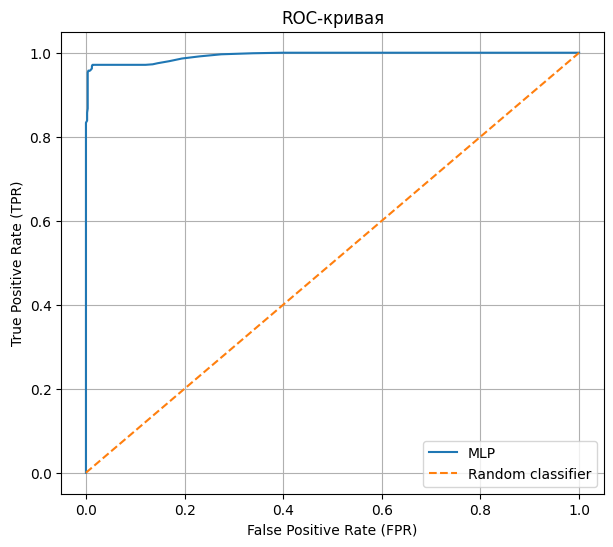

In [57]:
y_scores = mlp.predict_proba(X_test)[:, 1]
thresholds = np.linspace(0, 1, 100)

tpr_values = []
fpr_values = []

for threshold in thresholds:

    y_pred = (y_scores >= threshold).astype(int)

    TP = 0
    TN = 0
    FP = 0
    FN = 0

    for real, predicted in zip(y_test, y_pred):

        if real == 1 and predicted == 1:
            TP += 1

        elif real == 0 and predicted == 0:
            TN += 1

        elif real == 0 and predicted == 1:
            FP += 1

        elif real == 1 and predicted == 0:
            FN += 1

    TPR = TP / (TP + FN) if (TP + FN) != 0 else 0
    FPR = FP / (FP + TN) if (FP + TN) != 0 else 0

    tpr_values.append(TPR)
    fpr_values.append(FPR)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_values,
    tpr_values,
    label="MLP"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC-кривая")
plt.legend()
plt.grid()

plt.show()